# 06 · Real-world assets: a replication study on tokenized real estate

**Module 4 · DeFi II — Topic 3, Lab 4.8**

Lecture 4.7 introduced RWAs through two lenses. This lab applies the **quantitative-finance** lens, and it does so as a **replication study**: we take the methodology and the results of a peer-reviewed paper and re-run them on *current, live* on-chain data, then ask whether the findings still hold and, if not, **why**.

**The paper.** Swinkels (2023), *Empirical evidence on the ownership and liquidity of real estate tokens*, **Financial Innovation** 9, Article 45. It studied **58** RealT properties (mostly Detroit) tokenized on **Ethereum**, Oct 2019 – Feb 2021, and reported:
- **Ownership concentration** via the adjusted Herfindahl–Hirschman index `HHI* = (HHI − 1/N)/(1 − 1/N)`, with `HHI = Σ sᵢ²`: a **median of 254 owners** per property and a **median HHI\* ≈ 2.0 %** (dispersed ownership — fractional ownership is real).
- **Liquidity**: monthly turnover fell from ≈ **15 %** early to ≈ **5 %** (roughly one trade every two years per token).
- **Price**: token prices tracked the local (Case–Shiller Detroit) **house-price index** over long horizons.

**What changed since.** RealT migrated to **Gnosis Chain** (fees ≈ \$20/tx on Ethereum → < \$0.01 on Gnosis) and grew from 58 to **800+** tokens. We re-measure ownership concentration on live Gnosis data and compare.

> Free data, no API key: RealT community API (token list, prices) + the Gnosis block-explorer API (holders, transfers). Every response is cached under `data/rwa/`, so the notebook re-runs offline and reproducibly. **Delete a cache file to pull fresh live data.**

In [1]:
%matplotlib inline
import os, json, time, hashlib
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

CACHE = "data/rwa"; os.makedirs(CACHE, exist_ok=True)
REALT = "https://api.realtoken.community/v1"     # token list + market data (free, no key)
GNOSIS = "https://gnosis.blockscout.com/api/v2"  # holders / transfers (free, no key; redirects to the live explorer)

def cget(url, key=None, pause=0.4):
    """GET JSON with a local cache. `key` names the cache file; delete it to force a fresh pull."""
    key = key or hashlib.md5(url.encode()).hexdigest()
    path = os.path.join(CACHE, key + ".json")
    if os.path.exists(path):
        return json.load(open(path))
    for _ in range(3):
        try:
            r = requests.get(url, headers={"User-Agent": "epicode-web3-lab"}, timeout=40)
            if r.status_code == 200:
                data = r.json(); json.dump(data, open(path, "w")); time.sleep(pause); return data
        except requests.RequestException:
            pass
        time.sleep(1.5)
    raise RuntimeError("failed: " + url)

## 1 · The current RealT universe (RealT API)

We pull the live token list and keep the Detroit properties that exist on Gnosis — the same city Swinkels studied.

In [2]:
tokens = cget(f"{REALT}/token", key="realt_tokens")
detroit = [t for t in tokens if t.get("gnosisContract") and "DETROIT" in (t.get("symbol") or "")]
print(f"RealT tokens total: {len(tokens)}   |   Detroit tokens on Gnosis: {len(detroit)}")
print(f"(Swinkels studied 58 properties in 2019-2021; RealT now lists {len(tokens)} tokens.)")
pd.DataFrame([{ "property": t["shortName"], "price_$": t["tokenPrice"] } for t in detroit[:6]])

RealT tokens total: 829   |   Detroit tokens on Gnosis: 574
(Swinkels studied 58 properties in 2019-2021; RealT now lists 829 tokens.)


,property,price_$
0,15777 Ardmore,48.37
1,14319 Rosemary,49.69
2,14078 Carlisle,54.25
3,13895 Saratoga,58.50
4,4380 Beaconsfield,53.88
5,17813 Bradford,51.33


## 2 · Ownership concentration on live Gnosis data (HHI\*)

For a sample of tokens we fetch every holder and its balance, **separate contract addresses from real (EOA) holders**, and compute `HHI*` over the real holders. The contract separation is essential: on Gnosis a large share of each token sits in the **AMB bridge mediator** and in **AMM liquidity pools**, which are infrastructure, not owners.

In [3]:
def holders_of(addr, max_pages=6):
    """Fetch holders (paginated) and token info for one RealT token on Gnosis."""
    info = cget(f"{GNOSIS}/tokens/{addr}", key=f"info_{addr}")
    items, url, page = [], f"{GNOSIS}/tokens/{addr}/holders", 0
    while url and page < max_pages:
        r = cget(url, key=f"holders_{addr}_{page}")
        items += r.get("items", []); page += 1
        npp = r.get("next_page_params")
        url = f"{GNOSIS}/tokens/{addr}/holders?" + requests.compat.urlencode(npp) if npp else None
    return info, items

def hhi_star(shares):
    """Adjusted Herfindahl-Hirschman index over ownership shares (Swinkels 2023)."""
    N = len(shares)
    if N < 2: return 1.0
    hhi = sum(s * s for s in shares)
    return (hhi - 1 / N) / (1 - 1 / N)

def is_contract(h):
    a = h.get("address"); return isinstance(a, dict) and a.get("is_contract")

rows = []
for t in detroit[:12]:                              # 12 tokens keeps it quick; raise for your own runs
    info, hs = holders_of(t["gnosisContract"])
    eoa = [h for h in hs if not is_contract(h)]
    con = [h for h in hs if is_contract(h)]
    total = sum(int(h["value"]) for h in hs) or 1
    contract_share = sum(int(h["value"]) for h in con) / total
    eoa_total = sum(int(h["value"]) for h in eoa) or 1
    shares = [int(h["value"]) / eoa_total for h in eoa]
    rows.append({"property": t["shortName"],
                 "holders": int(info.get("holders_count") or len(hs)),
                 "real_holders": len(eoa),
                 "HHI*_%": round(hhi_star(shares) * 100, 1),
                 "contract_held_%": round(contract_share * 100, 1)})

live = pd.DataFrame(rows)
live

,property,holders,real_holders,HHI*_%,contract_held_%
0,15777 Ardmore,182,150,5.0,74.3
1,14319 Rosemary,163,137,4.7,67.3
2,14078 Carlisle,157,135,1.2,80.0
3,13895 Saratoga,168,149,2.2,76.1
4,4380 Beaconsfield,161,137,4.3,72.8
5,17813 Bradford,159,141,1.5,80.8
6,15796 Hartwell,156,135,4.5,67.9
7,9717 Everts,191,166,3.6,71.4
8,19201 Westphalia,206,178,0.8,73.3
9,19163 Mitchell,172,144,1.3,77.9


In [4]:
current = {"median holders": int(live.holders.median()),
           "median real holders": int(live.real_holders.median()),
           "median HHI*_%": round(live["HHI*_%"].median(), 1),
           "median contract-held_%": round(live["contract_held_%"].median(), 1)}
compare = pd.DataFrame({
    "Swinkels 2023 (Ethereum)": {"median holders": 254, "median real holders": 254,
                                 "median HHI*_%": 2.0, "median contract-held_%": 0.0},
    "Current (Gnosis, live)":   current,
}).T
compare

,median holders,median real holders,median HHI*_%,median contract-held_%
Swinkels 2023 (Ethereum),254.0,254.0,2.0,0.0
"Current (Gnosis, live)",165.0,142.0,1.9,75.2


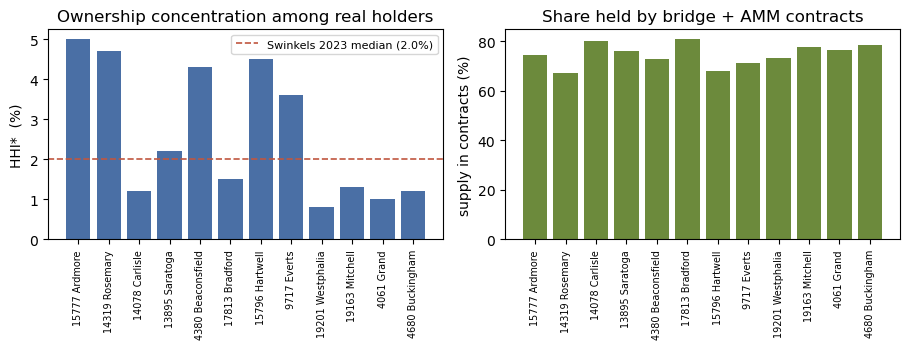

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.6))
ax[0].bar(live.property, live["HHI*_%"], color="#4a6fa5"); ax[0].axhline(2.0, color="#c05640", ls="--", lw=1.2, label="Swinkels 2023 median (2.0%)")
ax[0].set_ylabel("HHI*  (%)"); ax[0].set_title("Ownership concentration among real holders")
ax[0].tick_params(axis="x", rotation=90, labelsize=7); ax[0].legend(fontsize=8)
ax[1].bar(live.property, live["contract_held_%"], color="#6c8a3c")
ax[1].set_ylabel("supply in contracts (%)"); ax[1].set_title("Share held by bridge + AMM contracts")
ax[1].tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.show()

## 3 · Do the findings replicate? And why (or why not)?

- **Fractional ownership — confirmed.** Among real holders, `HHI*` is a few per cent, the same order as Swinkels' 2.0 %: ownership is genuinely dispersed. The core democratization finding survives the migration.
- **Fewer direct holders.** The median holder count per token is lower than the paper's 254 — partly because much of the float now lives in **AMM pools** rather than in individual wallets.
- **A new phenomenon: contract-held supply.** Roughly **three-quarters** of each token now sits in **contracts** — the Gnosis **AMB bridge mediator** (tokens bridged from Ethereum) and **liquidity pools**. In Swinkels' 2019–2021 Ethereum data this did not exist.

**Why has the landscape changed?** RealT moved to Gnosis Chain because Ethereum fees (≈ \$20/transaction in Feb 2021, which Swinkels found suppressed trading) made small real-estate trades uneconomic. On Gnosis, fees are negligible, so tokens are bridged (locked in the mediator) and supplied to AMMs for liquidity. The **liquidity gap** the paper identified is being addressed structurally — by moving to a cheaper chain and adding automated market makers — which in turn reshapes the on-chain ownership picture the paper measured.

## 4 · Doing this at scale with Dune Analytics

**What Dune is.** [Dune Analytics](https://dune.com) is a community platform that indexes raw blockchain data into queryable SQL tables (decoded transactions, ERC-20 transfers, DEX trades, prices) across many chains, including Gnosis. Anyone can write a query, publish a chart, and assemble dashboards; results are shareable; viewing is free, but running a new query needs a Dune account on a trial or paid plan, as the free tier is view-only. It is the standard tool for the kind of on-chain analytics this lab does by hand — instead of paging a REST API, you write one SQL query over pre-indexed data.

**A concrete query.** The holder and transfer analysis above can be expressed directly in Dune SQL. For example, monthly transfer turnover for a RealT token on Gnosis:

```sql
-- Monthly transfer volume / supply for one RealT token on Gnosis (run on dune.com)
with xfers as (
    select date_trunc('month', evt_block_time) as month,
           sum(cast(value as double) / 1e18)    as tokens_moved
    from erc20_gnosis.evt_Transfer
    where contract_address = 0xFe17C3C0B6F38cF3bD8bA872bEE7a18Ab16b43fB   -- 15777 Ardmore
    group by 1
)
select month, tokens_moved, tokens_moved / 1300.0 as monthly_turnover   -- 1300 = total supply
from xfers order by month;
```

Paste it into a new query at dune.com, pick the Gnosis dataset, and run it (this needs a Dune trial or paid plan; the free tier is view-only, so the exercise instead computes turnover from the free explorer endpoint). To compare with Swinkels' 15 %→5 % monthly turnover, read `monthly_turnover` down the result. Dune's `dex.trades` table further lets you isolate *genuine* DEX trades from bridge/AMM-internal transfers, which is the refinement the paper's liquidity measure needs.

## Your task

1. **Extend the sample.** Raise the token count (and `max_pages`) and recompute the medians; how stable is HHI* across the RealT universe?
2. **Measure turnover.** Using the explorer's `/transfers` endpoint (free, no key), compute the monthly turnover for one token and compare it with Swinkels' 15%→5%. Is trading higher now that gas is cheap?
3. **Identify the infrastructure.** List the contract holders (bridge mediator, AMM pools) for one token and confirm they explain the ~75% contract-held share.
4. **The underlying index.** Download the Case-Shiller Detroit house-price index from FRED (series `DEXRSA`, a free CSV: https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXRSA) and report how much Detroit prices rose over Swinkels' 2019–2021 window and since. The paper found token prices tracked this index; note that replicating that tracking *directly* needs secondary-market (DEX) trade prices, not RealT's fixed quoted price.

Worked solutions are in the separate solutions notebook `06_rwa_realt_replication_solutions.ipynb` — attempt the exercises before opening it.

## Reference

Swinkels, L. (2023). *Empirical evidence on the ownership and liquidity of real estate tokens.* Financial Innovation 9, Article 45. DOI 10.1186/s40854-022-00427-5. Data: RealT community API; Gnosis block-explorer API; Dune Analytics. Reference solution for Lab 4.8.